# AirfRANS: exploring the raw data, and the decisions it drove

This notebook is the exploration behind the project's ETL (`src/etl/`). Every choice the pipeline makes about the data was made by looking at the data first:

- which split to train and test on;
- how the graph for the graph neural network is built;
- how the airfoil surface is found, and which way its normals point;
- what the pressure field means;
- how the result is checked and stored.

Each section shows **what the data showed, the options considered, the one chosen, and why the others were rejected**, with the evidence in the output underneath. Some first conclusions turned out to be wrong when measured more carefully, and those corrections are kept in, because they are part of why the pipeline looks the way it does.

**Inputs.** Sections 1–6 read the raw snapshot `data/raw/airfrans/<date>/`, written by `python -m src.ingest.airfrans`. Sections 7–10 also read the ETL's outputs, written by `python -m src.etl.pipeline`. The notebook runs in the project's Jupyter container (`docker compose --profile dev up -d`) and takes a few minutes on a laptop.

**Contents**
1. Where the data comes from
2. The dataset at a glance, and the split
3. One simulation up close
4. Building the graph
5. Finding the airfoil surface
6. Which way the surface normals point
7. What `p` is, and checking folder names against the physics
8. Target distributions and normalisation
9. What reading costs
10. How it is stored
11. Summary of decisions

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.tri as mtri
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.colors import LinearSegmentedColormap, LogNorm, TwoSlopeNorm
from matplotlib.path import Path as PolygonPath
from scipy.spatial import cKDTree
from vtkmodules.util.numpy_support import vtk_to_numpy
from vtkmodules.vtkIOXML import vtkXMLUnstructuredGridReader

from src.config import AIRFRANS_RAW_ROOT, INTERIM_ROOT, PROCESSED_ROOT
from src.etl import quality
from src.etl.mesh import match_points, point_index, quad_edges
from src.etl.names import CHORD_M, NU_M2_S, parse_simulation_name
from src.etl.pipeline import find_snapshot
from src.etl.vtk_io import read_polyline, read_simulation, simulation_files

# Chart style: a light surface, recessive grid and axes, colours used in a fixed order.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "axes.edgecolor": AXIS,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA]),
    "lines.linewidth": 2, "legend.frameon": False,
})
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
SEQ_ORANGE = LinearSegmentedColormap.from_list("seq_orange", ["#fbe3d8", "#f5b08f", "#eb6834", "#b8461d", "#7a2c10"])
DIVERGING = LinearSegmentedColormap.from_list(
    "blue_grey_red", ["#0d366b", "#3987e5", "#b7d3f6", "#f0efec", "#f4c4c0", "#e34948", "#8f2423"]
)
pd.set_option("display.precision", 4)


def timed(fn, *args):
    """(result, seconds)."""
    started = time.perf_counter()
    result = fn(*args)
    return result, time.perf_counter() - started


def loop_order(line_connectivity: np.ndarray) -> np.ndarray:
    """Point indices of a closed polyline made of 2-point segments, in walking order."""
    neighbours: dict[int, list[int]] = {}
    for a, b in line_connectivity.reshape(-1, 2).tolist():
        neighbours.setdefault(a, []).append(b)
        neighbours.setdefault(b, []).append(a)
    start = int(line_connectivity[0])
    order, previous, current = [start], None, start
    while True:
        first, second = neighbours[current]
        following = second if first == previous else first
        if following == start:
            return np.array(order)
        order.append(following)
        previous, current = current, following


SNAPSHOT, SOURCE = find_snapshot(AIRFRANS_RAW_ROOT)
DATASET = SNAPSHOT / "Dataset"
MANIFEST = json.loads((DATASET / "manifest.json").read_text())
NAMES = sorted(p.name for p in DATASET.iterdir() if p.is_dir())
INTERIM = INTERIM_ROOT / "airfrans" / SNAPSHOT.name
PROCESSED = PROCESSED_ROOT / "airfrans" / SNAPSHOT.name
print(f"raw snapshot {SNAPSHOT.name}: {len(NAMES)} simulation directories")

raw snapshot 2026-11-20: 1000 simulation directories


## 1. Where the data comes from

AirfRANS (Bonnet et al., NeurIPS 2022 Datasets and Benchmarks) is 1,000 two-dimensional RANS simulations of NACA airfoils, solved with OpenFOAM's k-ω SST model. It is licensed ODbL-1.0. The ingestion step downloads the authors' original `Dataset.zip` once and records its provenance:

| Option | Verdict |
|---|---|
| **The raw archive from the authors' server** | **Chosen.** The original VTK files, mesh connectivity included, pinned by size, ETag and SHA-256 as an immutable snapshot. |
| PyTorch Geometric's `AirfRANS` dataset | Rejected. It loads a preprocessed, pickled file of point clouds without the mesh cells. That loses the graph this project trains on, and the original mesh needed to send predictions back to ParaView. |
| The `airfrans` Python package | Rejected. It reads the same files through PyVista, adding a dependency, and has not had a release since 2023. |

In [2]:
pd.Series({key: value for key, value in SOURCE.items() if key != "manifest_splits"}, name="source.json").to_frame()

,source.json
source,AirfRANS
url,https://data.isir.upmc.fr/extrality/NeurIPS_20...
etag,"""62f519b5-255c76d39"""
last_modified,"Thu, 11 Aug 2022 15:01:09 GMT"
size_bytes,10029067577
sha256,6b301d75dee77fc6c7de6e551c44332be4acc84e30b253...
license,ODbL-1.0
citation,"Bonnet et al., AirfRANS, NeurIPS 2022 Datasets..."
downloaded_at_utc,2026-11-21T13:58:57+00:00
ingest_code_commit,d7bad007c559ff789b84460d21672161c9e98a9b


## 2. The dataset at a glance, and the split

Every simulation directory is named `airFoil2D_SST_<U∞>_<angle of attack>_<NACA parameters>`. The Reynolds number follows from U∞ with the dataset's 1 m chord and ν = 1.56·10⁻⁵ m²/s. The manifest lists seven splits.

In [3]:
sims = pd.DataFrame(
    [{"name": n, "u_inf": q.u_inf, "aoa_deg": q.aoa_deg, "reynolds": q.reynolds, "naca_digits": q.naca_digits}
     for n, q in ((n, parse_simulation_name(n)) for n in NAMES)]
)
for split, members in MANIFEST.items():
    sims[split] = sims.name.isin(set(members))

train, test = set(MANIFEST["full_train"]), set(MANIFEST["full_test"])
print(f"full_train ∩ full_test: {len(train & test)} simulations; together they cover all {len(NAMES)}: {train | test == set(NAMES)}")
print(f"NACA 4-digit: {(sims.naca_digits == 4).sum()}, 5-digit: {(sims.naca_digits == 5).sum()}")
display(pd.Series({k: len(v) for k, v in MANIFEST.items()}, name="simulations").to_frame().T)
sims[["u_inf", "aoa_deg", "reynolds"]].describe().loc[["min", "50%", "max"]]

full_train ∩ full_test: 0 simulations; together they cover all 1000: True
NACA 4-digit: 489, 5-digit: 511


,full_train,scarce_train,reynolds_train,aoa_train,full_test,reynolds_test,aoa_test
simulations,800,200,504,804,200,496,196


,u_inf,aoa_deg,reynolds
min,31.283,-4.9400,2.0053e+06
50%,62.404,3.9935,4.0003e+06
max,93.592,14.9260,5.9995e+06


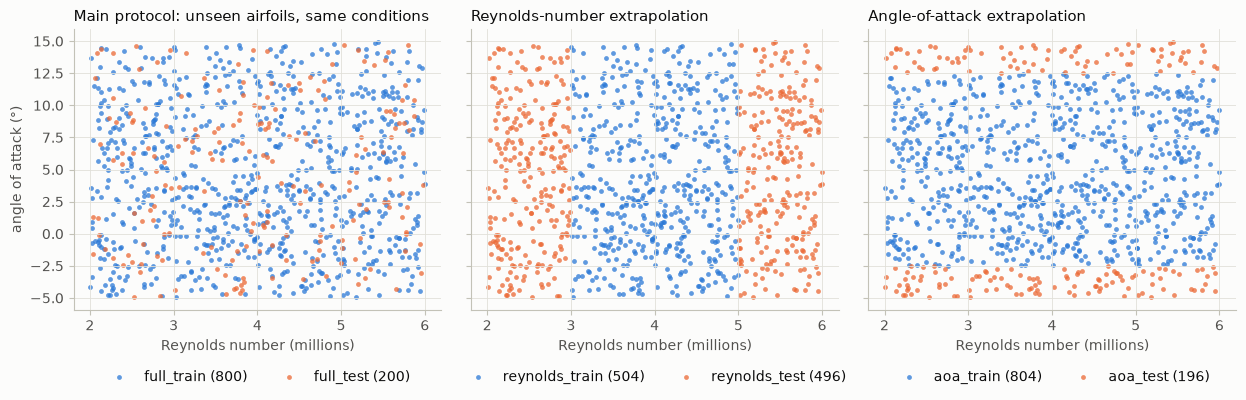

In [4]:
panels = [
    ("full_train", "full_test", "Main protocol: unseen airfoils, same conditions"),
    ("reynolds_train", "reynolds_test", "Reynolds-number extrapolation"),
    ("aoa_train", "aoa_test", "Angle-of-attack extrapolation"),
]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (train_split, test_split, title) in zip(axes, panels):
    for split, colour in ((train_split, BLUE), (test_split, ORANGE)):
        rows = sims[sims[split]]
        ax.scatter(rows.reynolds / 1e6, rows.aoa_deg, s=12, color=colour, alpha=0.75, linewidths=0,
                   label=f"{split} ({len(rows)})")
    ax.set_title(title)
    ax.set_xlabel("Reynolds number (millions)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
axes[0].set_ylabel("angle of attack (°)")
fig.subplots_adjust(bottom=0.27, wspace=0.08)

**What it shows.** Reynolds numbers span 2–6 million and angles of attack −5° to 15°, filled evenly. `full_test` is spread across the same region as `full_train`, so testing on it means **new geometries under familiar conditions**. The two extrapolation splits cut the region instead, holding out high Reynolds numbers or the edges of the angle range.

**Decision: split by simulation, using the manifest's `full_train` / `full_test`. Validation is 80 simulations drawn from `full_train` with a fixed seed.**

| Option | Verdict |
|---|---|
| Random split of mesh points | Rejected. Points of the same airfoil would land on both sides, so the model could interpolate a test airfoil's field from its own training points. The score would say nothing about airfoils the model has never seen, which is the point of a surrogate. |
| A home-made random split of simulations | Rejected. Valid, but not comparable with the published benchmark. |
| **Manifest `full_train` / `full_test`** | **Chosen.** By simulation, published, comparable. Each test airfoil is a geometry the model never saw. |
| The extrapolation splits | Kept as flags in `simulations.parquet` for a later, harder check; not the main protocol. |

## 3. One simulation up close

Each simulation has three files:

- `_internal.vtu`: the volume mesh with the flow fields;
- `_aerofoil.vtp`: the airfoil surface, a polyline;
- `_freestream.vtp`: the outer boundary.

Here is one simulation at about 10° angle of attack.

In [5]:
example = sims.loc[(sims.aoa_deg - 10).abs().idxmin(), "name"]
params = parse_simulation_name(example)
raw, read_s = timed(read_simulation, DATASET / example)
mesh, aerofoil = raw.mesh, raw.aerofoil
xy = mesh.points[:, :2]
U, p, nut, dist = (mesh.point_data[k] for k in ("U", "p", "nut", "implicit_distance"))
quads = mesh.cell_connectivity.reshape(-1, 4)
outline = aerofoil.points[loop_order(aerofoil.line_connectivity), :2]

print(example)
print(f"U∞ = {params.u_inf} m/s, AoA = {params.aoa_deg}°, Re = {params.reynolds / 1e6:.2f} million")
print(f"{mesh.n_points:,} points, {mesh.n_cells:,} cells, cell types {mesh.cell_types.tolist()} (VTK 9 = quad), read in {read_s:.2f} s")
print(f"z of every point: {np.unique(mesh.points[:, 2])}  → a 2D slice of a one-cell-thick 3D mesh")
exact = np.array_equal(mesh.points.astype(np.float32).astype(np.float64), mesh.points)
print(f"mesh coordinates stored as {mesh.points.dtype}, every value an exact float32 number: {exact}")
print(f"surface-file coordinates stored as {aerofoil.points.dtype}")
columns = {"U_x": U[:, 0], "U_y": U[:, 1], "U_z": U[:, 2], "p": p, "nut": nut, "implicit_distance": dist}
pd.DataFrame(
    {name: {"dtype": str(v.dtype), "min": float(v.min()), "max": float(v.max()), "NaN": int(np.isnan(v).sum())}
     for name, v in columns.items()}
).T

airFoil2D_SST_37.983_9.999_6.128_2.638_10.544
U∞ = 37.983 m/s, AoA = 9.999°, Re = 2.43 million
182,430 points, 181,158 cells, cell types [9] (VTK 9 = quad), read in 0.36 s
z of every point: [0.5]  → a 2D slice of a one-cell-thick 3D mesh
mesh coordinates stored as float64, every value an exact float32 number: True
surface-file coordinates stored as float32


,dtype,min,max,NaN
U_x,float32,-28.1032,67.6713,0
U_y,float32,-6.8987,75.8818,0
U_z,float32,-0.0,0.0,0
p,float32,-2385.2451,721.897,0
nut,float32,0.0,0.0174,0
implicit_distance,float64,-3.534,-0.0,0


**A wrong first reading.** U_z looks like exactly 0 in a quick summary. My first probe printed minima and maxima rounded to six decimals and showed `0.0`, so the first version of the quality gate required U_z == 0. It then rejected **every** simulation. The unrounded values:

In [6]:
u_z = float(np.abs(U[:, 2].astype(np.float64)).max())
print(f"largest |U_z| = {u_z:.2e} m/s, i.e. {u_z / params.u_inf:.1e} × U∞")
print(f"the same number rounded to six decimals: {round(u_z, 6)}")
print(f"nodes where U_z is exactly 0: {(U[:, 2] == 0).mean():.1%}")

largest |U_z| = 1.37e-17 m/s, i.e. 3.6e-19 × U∞
the same number rounded to six decimals: 0.0
nodes where U_z is exactly 0: 1.2%


U_z is solver round-off, about twelve orders of magnitude below the flow (up to 2.8·10⁻¹² of U∞ in a 50-simulation sample). The gate now requires |U_z| ≤ 10⁻⁶ U∞, which allows round-off but still rejects a genuinely 3D field, and the ETL drops the column.

**The mesh.** The cells grow from microscopic at the wall to coarse in the far field. That's the price of resolving the boundary layer, and it matters for the next two sections.

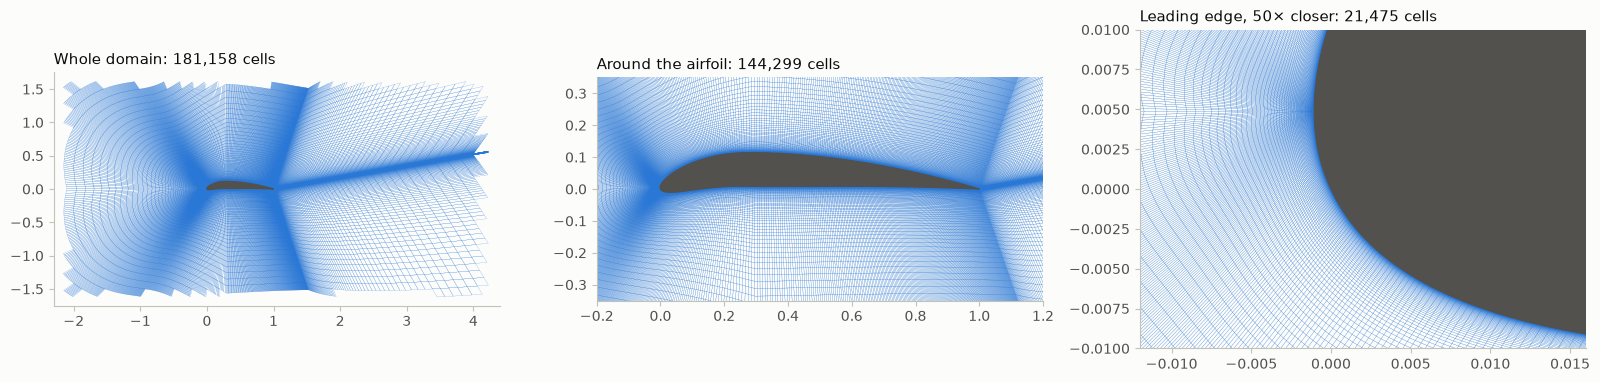

In [7]:
def quads_in(x0, x1, y0, y1):
    inside = (xy[:, 0] >= x0) & (xy[:, 0] <= x1) & (xy[:, 1] >= y0) & (xy[:, 1] <= y1)
    return quads[inside[quads].any(axis=1)]


windows = [
    ("Whole domain", (-2.3, 4.4, -1.75, 1.75)),
    ("Around the airfoil", (-0.2, 1.2, -0.35, 0.35)),
    ("Leading edge, 50× closer", (-0.012, 0.016, -0.01, 0.01)),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, (title, (x0, x1, y0, y1)) in zip(axes, windows):
    cells = quads_in(x0, x1, y0, y1)
    ax.add_collection(PolyCollection(xy[cells], facecolors="none", edgecolors=BLUE,
                                     linewidths=0.12 if len(cells) > 20_000 else 0.4, rasterized=True))
    ax.fill(outline[:, 0], outline[:, 1], color=INK_2, zorder=3)
    ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", title=f"{title}: {len(cells):,} cells")
    ax.grid(False)
fig.tight_layout()

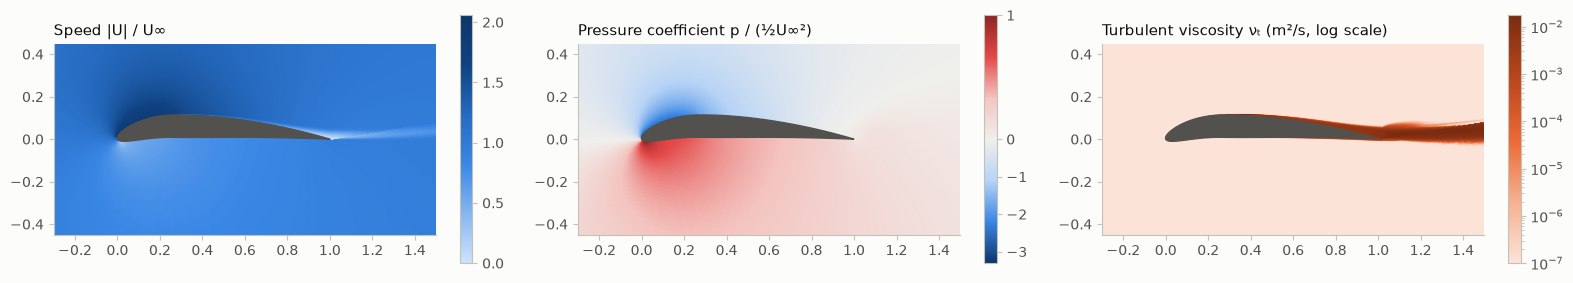

In [8]:
window = (-0.3, 1.5, -0.45, 0.45)
cells = quads_in(*window)
triangulation = mtri.Triangulation(xy[:, 0], xy[:, 1], np.vstack([cells[:, [0, 1, 2]], cells[:, [0, 2, 3]]]))
speed = np.hypot(U[:, 0], U[:, 1]) / params.u_inf
cp = p / (0.5 * params.u_inf**2)
fields = [
    ("Speed |U| / U∞", speed, SEQ_BLUE, None),
    ("Pressure coefficient p / (½U∞²)", cp, DIVERGING, TwoSlopeNorm(vmin=float(cp.min()), vcenter=0.0, vmax=1.0)),
    ("Turbulent viscosity νₜ (m²/s, log scale)", np.clip(nut, 1e-7, None), SEQ_ORANGE, LogNorm(1e-7, float(nut.max()))),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, (title, values, cmap, norm) in zip(axes, fields):
    image = ax.tripcolor(triangulation, values, cmap=cmap, norm=norm, shading="gouraud", rasterized=True)
    ax.fill(outline[:, 0], outline[:, 1], color=INK_2)
    ax.set(xlim=window[:2], ylim=window[2:], aspect="equal", title=title)
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.tight_layout()

**Point data or cell data?** The solver computes values at cell centres. The file carries those and an interpolated copy at the mesh points:

In [9]:
reader = vtkXMLUnstructuredGridReader()
reader.SetFileName(str(simulation_files(DATASET / example)[0]))
reader.Update()
cell_p = vtk_to_numpy(reader.GetOutput().GetCellData().GetArray("p"))
print(f"point values: {len(p):,}; cell values: {len(cell_p):,}")
print(f"stagnation pressure at the points {p.max():.3f}, at the cell centres {cell_p.max():.3f} m²/s²")

point values: 182,430; cell values: 181,158
stagnation pressure at the points 721.897, at the cell centres 721.932 m²/s²


**Decision: point data.** The graph's nodes are the mesh points, and the airfoil surface file's points are mesh points (section 5). Cell values would need a second, dual graph and their own surface mapping. The difference between the two is the interpolation, a fraction of a percent at the stagnation point.

## 4. Building the graph

A graph neural network passes messages along edges, so the edges decide which nodes can influence each other.

In [10]:
sdf = -dist  # distance to the airfoil, ≥ 0
edges = quad_edges(mesh.cell_connectivity, mesh.n_points)
degree = np.bincount(edges.ravel(), minlength=mesh.n_points)
surface_ids = match_points(point_index(xy), aerofoil.points[:, :2])
surface_segments = {tuple(sorted(pair)) for pair in surface_ids[aerofoil.line_connectivity.reshape(-1, 2)].tolist()}
polygon = PolygonPath(outline)


def through_the_airfoil(pairs: np.ndarray, near: float = 0.05) -> np.ndarray:
    """Edges passing through the solid body: a point along them lies inside the airfoil outline."""
    candidates = pairs[(sdf[pairs[:, 0]] < near) | (sdf[pairs[:, 1]] < near)]
    candidates = candidates[[tuple(e) not in surface_segments for e in candidates.tolist()]]
    inside = np.zeros(len(candidates), dtype=bool)
    for t in (0.25, 0.5, 0.75):
        inside |= polygon.contains_points(xy[candidates[:, 0]] * (1 - t) + xy[candidates[:, 1]] * t)
    return candidates[inside]


tree = cKDTree(xy)


def knn_graph(k: int) -> np.ndarray:
    _, nearest = tree.query(xy, k=k + 1)
    pairs = np.stack([np.repeat(np.arange(len(xy)), k), nearest[:, 1:].ravel()], axis=1)
    return np.unique(np.sort(pairs, axis=1), axis=0)


# The boundary layer: fluid nodes within 0.001 chord of the wall, each with the
# outward normal of its nearest surface point.
boundary_layer = (sdf > 0) & (sdf < 1e-3)
outward = -aerofoil.point_data["Normals"][:, :2].astype(np.float64)
_, nearest_wall = cKDTree(aerofoil.points[:, :2].astype(np.float64)).query(xy)
wall_normal = outward[nearest_wall]


def along_the_wall(pairs: np.ndarray) -> np.ndarray:
    """For each boundary-layer node, how many of its edges run along the wall (> 60° from the normal)."""
    both = np.concatenate([pairs, pairs[:, ::-1]])
    both = both[boundary_layer[both[:, 0]]]
    direction = xy[both[:, 1]] - xy[both[:, 0]]
    direction /= np.linalg.norm(direction, axis=1, keepdims=True)
    tangential = np.abs(np.einsum("ij,ij->i", direction, wall_normal[both[:, 0]])) < 0.5
    return np.bincount(both[tangential, 0], minlength=len(xy))[boundary_layer]


def spread(d):
    return f"{d.min()} / {np.median(d):.0f} / {d.max():,}"


radius_degree = tree.query_ball_point(xy, r=0.01, return_length=True) - 1
rows = {}
for label, pairs in (("mesh quad sides", edges), ("8-nearest neighbours", knn_graph(8)), ("32-nearest neighbours", knn_graph(32))):
    along = along_the_wall(pairs)
    rows[label] = {
        "edges": f"{len(pairs):,}",
        "neighbours per node, min / median / max": spread(np.bincount(pairs.ravel(), minlength=len(xy))),
        "edges through the airfoil": f"{len(through_the_airfoil(pairs)):,}",
        "boundary-layer nodes with no neighbour along the wall": f"{(along == 0).mean():.1%}",
    }
rows["radius 0.01 chord"] = {
    "edges": f"{radius_degree.sum() // 2:,}",
    "neighbours per node, min / median / max": spread(radius_degree),
    "edges through the airfoil": "(not built)",
    "boundary-layer nodes with no neighbour along the wall": "(not built)",
}
knn = knn_graph(8)
print(f"boundary-layer nodes (within 0.001 chord of the wall): {boundary_layer.sum():,}; "
      f"radius graph: {(radius_degree == 0).sum():,} nodes with no neighbour at all")
pd.DataFrame(rows).T

boundary-layer nodes (within 0.001 chord of the wall): 51,897; radius graph: 6,412 nodes with no neighbour at all


,edges,"neighbours per node, min / median / max",edges through the airfoil,boundary-layer nodes with no neighbour along the wall
mesh quad sides,"363,588",2 / 4 / 5,0,0.0%
8-nearest neighbours,"828,474",8 / 9 / 13,0,85.7%
32-nearest neighbours,"3,429,665",32 / 36 / 56,83,71.3%
radius 0.01 chord,"255,808,945","0 / 253 / 20,455",(not built),(not built)


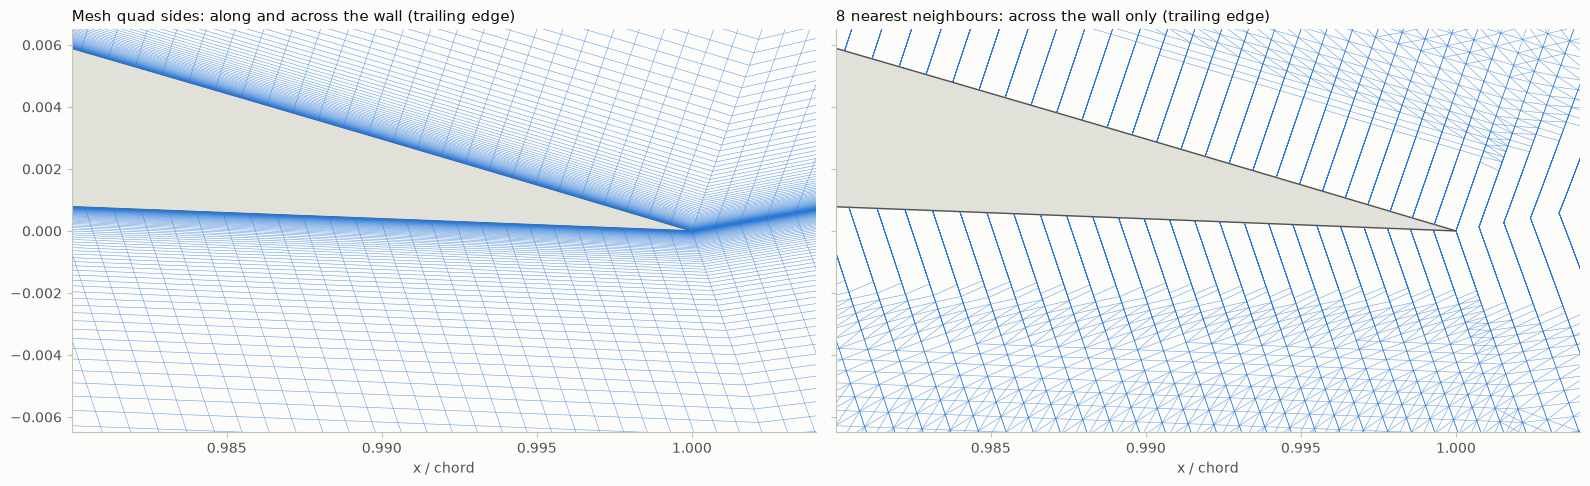

In [11]:
te = outline[np.argmax(outline[:, 0])]
x0, x1, y0, y1 = te[0] - 0.02, te[0] + 0.004, te[1] - 0.0065, te[1] + 0.0065


def segments_near(pairs):
    ends = xy[pairs]
    keep = ((ends[..., 0] >= x0) & (ends[..., 0] <= x1) & (ends[..., 1] >= y0) & (ends[..., 1] <= y1)).any(axis=1)
    return ends[keep]


fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), sharey=True)
for ax, (title, pairs) in zip(
    axes, [("Mesh quad sides: along and across the wall", edges), ("8 nearest neighbours: across the wall only", knn)]
):
    ax.fill(outline[:, 0], outline[:, 1], color=GRID, zorder=0)
    ax.plot(outline[:, 0], outline[:, 1], color=INK_2, lw=1, zorder=1)
    ax.add_collection(LineCollection(segments_near(pairs), colors=BLUE, linewidths=0.4, alpha=0.7, zorder=2))
    ax.set(xlim=(x0, x1), ylim=(y0, y1), aspect="equal", title=f"{title} (trailing edge)", xlabel="x / chord")
    ax.grid(False)
fig.tight_layout()

**A third wrong first reading.** I expected k-nearest neighbours to fail by connecting the upper and lower surfaces through the thin trailing edge. With k = 8 the table says otherwise: 0 such edges, because this mesh is fine enough there. The plot shows the real problem. Boundary-layer cells are extremely flat, so a node's nearest neighbours are the nodes stacked above and below it, **across** the wall. Its neighbours **along** the wall are farther away than all of those, so k-NN never reaches them, and most boundary-layer nodes have no neighbour along the wall at all.

Raising k doesn't escape this, it trades one problem for the other. At k = 32 most boundary-layer nodes *still* lack a neighbour along the wall, and the edges through the trailing edge I'd first expected now appear. The boundary layer is exactly where the flow along the surface matters most, for the pressure that becomes lift.

**Decision: edges are the sides of the mesh's quads** (one undirected edge per side, stored `src < dst`).

| Option | Verdict |
|---|---|
| **Mesh connectivity** | **Chosen.** It is the solver's own notion of "neighbour", with no parameter to tune: about four neighbours per node, two of them along the wall throughout the boundary layer, and no edge through the solid body. |
| k-nearest neighbours | Rejected. In the flat boundary-layer cells it connects nodes across the wall but not along it, and a larger k starts cutting through the airfoil before it fixes that (table above). |
| Radius graph | Rejected. With cells ranging from microscopic at the wall to coarse in the far field, any single radius gives thousands of neighbours in the boundary layer and none at all far away. |

## 5. Finding the airfoil surface

The models need to know which nodes lie on the wall: for surface normals as an input, and for integrating pressure into lift. There are three independent markers.

In [12]:
on_match = np.zeros(mesh.n_points, dtype=bool)
on_match[surface_ids[surface_ids >= 0]] = True
no_slip = (U[:, 0] == 0) & (U[:, 1] == 0)
on_wall = dist == 0
display(pd.DataFrame(
    {"nodes": [int(on_match.sum()), int(no_slip.sum()), int(on_wall.sum())],
     "same set as the coordinate match": [True, np.array_equal(no_slip, on_match), np.array_equal(on_wall, on_match)]},
    index=["exact coordinate match with _aerofoil.vtp", "velocity exactly 0 (no-slip)", "distance to the airfoil exactly 0"],
))
print(f"surface points with no exact match in the mesh: {int((surface_ids < 0).sum())} of {len(surface_ids)}")

fluid = sdf[~on_match]
print(f"closest fluid node to the wall: {fluid.min():.2e} chords")
pd.DataFrame(
    {"fluid nodes within ε of the wall (wrongly flagged as surface)": [int((fluid < eps).sum()) for eps in (1e-6, 1e-5, 1e-4, 1e-3)]},
    index=pd.Index([1e-6, 1e-5, 1e-4, 1e-3], name="tolerance ε (chords)"),
)

,nodes,same set as the coordinate match
exact coordinate match with _aerofoil.vtp,1029,True
velocity exactly 0 (no-slip),1029,True
distance to the airfoil exactly 0,1029,True


surface points with no exact match in the mesh: 0 of 1029
closest fluid node to the wall: 1.52e-06 chords


,fluid nodes within ε of the wall (wrongly flagged as surface)
tolerance ε (chords),
1.0000e-06,0
1.0000e-05,4331
1.0000e-04,21961
1.0000e-03,51897


closest fluid node, over all 1000 meshes (34 s, two columns read per mesh): 1.09e-06 … 1.72e-06 chords


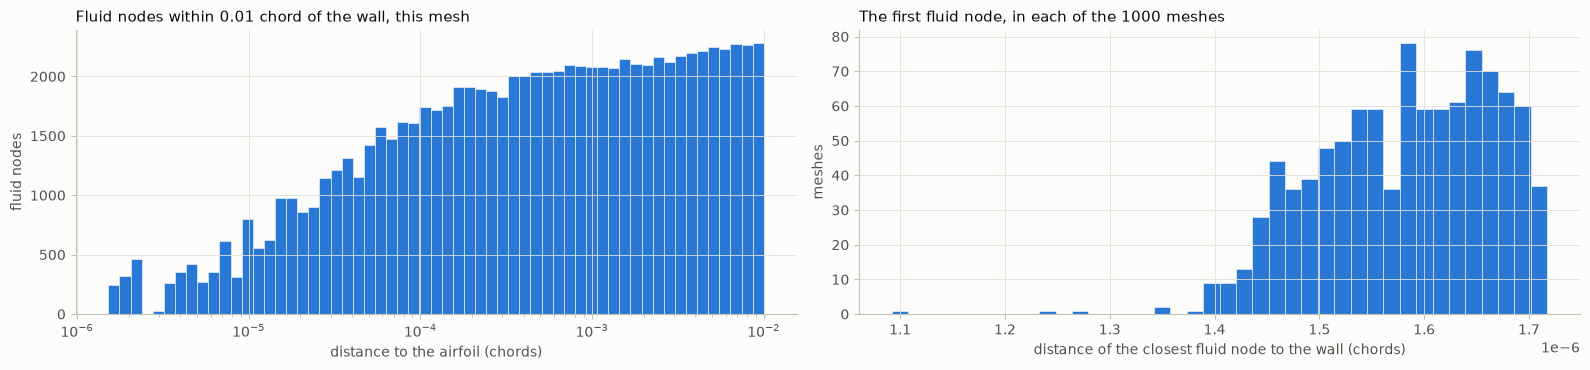

In [13]:
def closest_fluid_node(name: str) -> float:
    nodes = pq.read_table(INTERIM / "simulations" / name / "nodes.parquet", columns=["sdf", "is_surface"]).to_pandas()
    return float(nodes.sdf[~nodes.is_surface].min())


first_fluid, seconds = timed(lambda: pd.Series({n: closest_fluid_node(n) for n in NAMES}))
print(f"closest fluid node, over all {len(first_fluid)} meshes ({seconds:.0f} s, two columns read per mesh): "
      f"{first_fluid.min():.2e} … {first_fluid.max():.2e} chords")

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
near_wall = fluid[fluid < 0.01]
axes[0].hist(near_wall, bins=np.logspace(np.log10(near_wall.min()), -2, 60), color=BLUE, edgecolor=SURFACE, linewidth=0.4)
axes[0].set(xscale="log", xlabel="distance to the airfoil (chords)", ylabel="fluid nodes",
            title="Fluid nodes within 0.01 chord of the wall, this mesh")
axes[1].hist(first_fluid, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
axes[1].set(xlabel="distance of the closest fluid node to the wall (chords)", ylabel="meshes",
            title=f"The first fluid node, in each of the {len(first_fluid)} meshes")
fig.tight_layout()

**Decision: exact coordinate match with the surface file, with the other two markers as cross-checks in the quality gate.**

The match is exact because both files hold the same numbers. The surface file stores float32 coordinates, and the mesh's float64 coordinates are all exact float32 values (section 3). A comparison has nothing to round.

| Option | Verdict |
|---|---|
| **Exact coordinate match** | **Chosen.** The surface file lists exactly the wall points, every one of them is found, and there is nothing to tune. |
| Distance below a tolerance ε | Rejected, though not because it can't work. Every mesh's first fluid node sits in a narrow band just above 10⁻⁶ chords (right-hand plot), so an ε around 10⁻⁷ would separate wall from fluid in this dataset. But it is a parameter tied to this mesh generator's first-cell height, a wrong choice fails silently (10⁻⁵ already flags thousands of fluid nodes in this one mesh, table above), and it gains nothing over an exact match. |
| Velocity exactly 0 | Rejected as the primary method: it depends on the solver writing exact zeros. Kept as a check. |

The ETL's quality gate (check G6) requires all three to agree for every simulation; section 7 shows the outcome over all 1,000.

## 6. Which way the surface normals point

The surface file carries a normal vector per point. Lift is the pressure force on the surface: **F = −∮ p n dl**, with **n pointing out of the body**. If the stored normals point the other way, every lift coefficient changes sign. The check below uses only the small surface files, so it runs over all 1,000 simulations.

In [14]:
def surface_lift(name: str) -> dict:
    """Pressure lift coefficient, integrated with the stored normals' orientation."""
    q = parse_simulation_name(name)
    surface = read_polyline(simulation_files(DATASET / name)[1])
    pts = surface.points[:, :2].astype(np.float64)
    a, b = surface.line_connectivity.reshape(-1, 2).T
    stored = surface.point_data["Normals"][:, :2].astype(np.float64)
    tangent = pts[b] - pts[a]
    perpendicular = np.stack([tangent[:, 1], -tangent[:, 0]], axis=1)  # |perpendicular| = segment length
    orientation = np.sign(np.einsum("ij,ij->i", perpendicular, stored[a] + stored[b]))
    p_segment = 0.5 * (surface.point_data["p"][a] + surface.point_data["p"][b]).astype(np.float64)
    force = -(p_segment[:, None] * perpendicular * orientation[:, None]).sum(axis=0)
    alpha = np.radians(q.aoa_deg)
    cl = force @ np.array([-np.sin(alpha), np.cos(alpha)]) / (0.5 * q.u_inf**2 * CHORD_M)
    return {"name": name, "aoa_deg": q.aoa_deg, "cl_stored": cl, "cl_flipped": -cl,
            "leading_edge_normal_x": stored[np.argmin(pts[:, 0]), 0]}


lift, seconds = timed(lambda: pd.DataFrame([surface_lift(n) for n in NAMES]))
print(f"{len(lift)} simulations in {seconds:.0f} s")
per_degree = 2 * np.pi * np.pi / 180
for column in ("cl_stored", "cl_flipped"):
    slope = np.polyfit(lift.aoa_deg, lift[column], 1)[0]
    print(f"{column:>11}: lift slope {slope:+.4f} per degree   (thin-airfoil theory: {per_degree:+.4f})")
print(f"leading-edge normal, x component as stored: {lift.leading_edge_normal_x.min():.5f} … {lift.leading_edge_normal_x.max():.5f}")

1000 simulations in 13 s
  cl_stored: lift slope -0.0986 per degree   (thin-airfoil theory: +0.1097)
 cl_flipped: lift slope +0.0986 per degree   (thin-airfoil theory: +0.1097)
leading-edge normal, x component as stored: 0.99998 … 1.00000


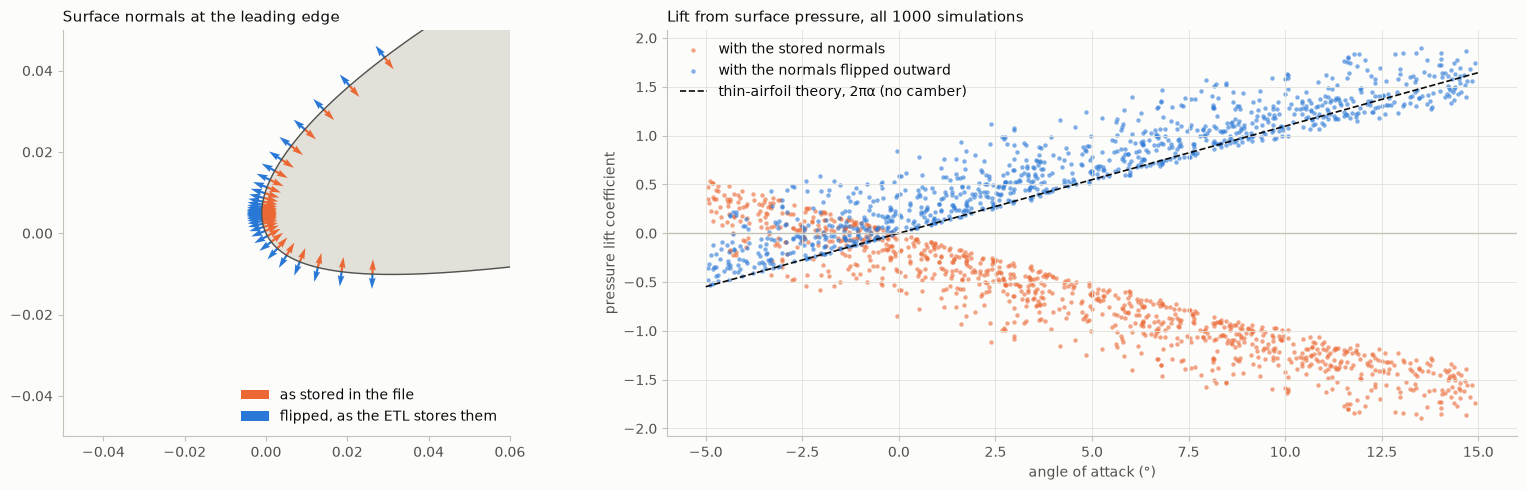

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.35]})
ax = axes[0]
pts, stored = aerofoil.points[:, :2], aerofoil.point_data["Normals"][:, :2]
front = np.flatnonzero(pts[:, 0] < 0.03)
front = front[:: max(1, len(front) // 36)]
ax.fill(outline[:, 0], outline[:, 1], color=GRID, zorder=0)
ax.plot(outline[:, 0], outline[:, 1], color=INK_2, lw=1)
ax.quiver(pts[front, 0], pts[front, 1], stored[front, 0], stored[front, 1], color=ORANGE, scale=30, width=0.005,
          label="as stored in the file")
ax.quiver(pts[front, 0], pts[front, 1], -stored[front, 0], -stored[front, 1], color=BLUE, scale=30, width=0.005,
          label="flipped, as the ETL stores them")
ax.set(xlim=(-0.05, 0.06), ylim=(-0.05, 0.05), aspect="equal", title="Surface normals at the leading edge")
ax.legend(loc="lower right")
ax.grid(False)

ax = axes[1]
ax.scatter(lift.aoa_deg, lift.cl_stored, s=10, color=ORANGE, alpha=0.6, linewidths=0, label="with the stored normals")
ax.scatter(lift.aoa_deg, lift.cl_flipped, s=10, color=BLUE, alpha=0.6, linewidths=0, label="with the normals flipped outward")
alpha = np.linspace(-5, 15, 50)
ax.plot(alpha, 2 * np.pi * np.radians(alpha), color=INK, lw=1.2, ls="--", label="thin-airfoil theory, 2πα (no camber)")
ax.axhline(0, color=AXIS, lw=1)
ax.set(xlabel="angle of attack (°)", ylabel="pressure lift coefficient",
       title=f"Lift from surface pressure, all {len(lift)} simulations")
ax.legend(loc="upper left")
fig.tight_layout()

**What it shows.** The stored normals point **into** the airfoil: at the leading edge they point downstream, into the body, in every simulation. Integrated as stored, lift *falls* as the angle of attack rises, which no airfoil does. Flipped, it rises at about 0.099 per degree, around 90 % of thin-airfoil theory's 2π per radian, which is what real sections with thickness and a boundary layer do. Most points sit above the dashed line because cambered sections already lift at zero angle.

**Decision: the ETL stores `normal = −Normals`, pointing into the fluid.** Gate check G8 confirms it for every simulation: after the flip, the leading-edge normal must point upstream. The alternative, keeping the stored vectors and remembering a minus sign in every later formula, would be one forgotten sign away from a model whose lift is wrong while its fields look right.

## 7. What `p` is, and checking folder names against the physics

The pressure at the stagnation point, where the flow comes to rest on the leading edge, is ½ρU∞² above the free stream. Its value in the file therefore says what `p` is.

max p / (½U∞²) on this airfoil: 1.0008


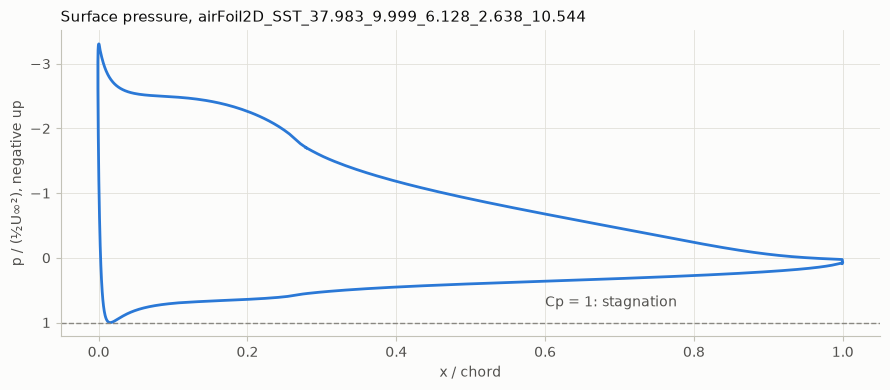

In [16]:
order = loop_order(aerofoil.line_connectivity)
order = np.append(order, order[0])  # close the loop
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(aerofoil.points[order, 0], aerofoil.point_data["p"][order] / (0.5 * params.u_inf**2), color=BLUE)
ax.axhline(1.0, color=MUTED, lw=1, ls="--")
ax.annotate("Cp = 1: stagnation", xy=(0.6, 1.0), xytext=(0.6, 0.75), color=INK_2)
ax.invert_yaxis()
ax.set(xlabel="x / chord", ylabel="p / (½U∞²), negative up", title=f"Surface pressure, {example}")
fig.tight_layout()
print(f"max p / (½U∞²) on this airfoil: {p.max() / (0.5 * params.u_inf**2):.4f}")

The maximum is ½U∞² to within 0.2 %, with no density in it. `p` is therefore **kinematic gauge pressure**: pressure divided by density, relative to the free stream, in m²/s². The ETL stores it as it is, and the pressure coefficient is simply `p / (½U∞²)`.

That gives a cross-check worth automating. The folder name says what U∞ and the angle of attack are, and the file has to agree. The stagnation ratio tests U∞, and the velocity on the upstream far-field boundary tests both U∞ and the angle. The ETL computes all three for every simulation (gate check G9). Here they are over all 1,000, with the gate's limits:

ETL: {'expected': 1000, 'processed': 1000, 'skipped': 0, 'failed': 0}, status 'complete'


,stagnation_ratio,inlet_speed_rel_err,inlet_angle_err_deg
min,1.0006,6.2429e-08,9.4009e-06
50%,1.0011,2.6206e-05,1.8672e-03
max,1.0020,5.3437e-05,4.4234e-03


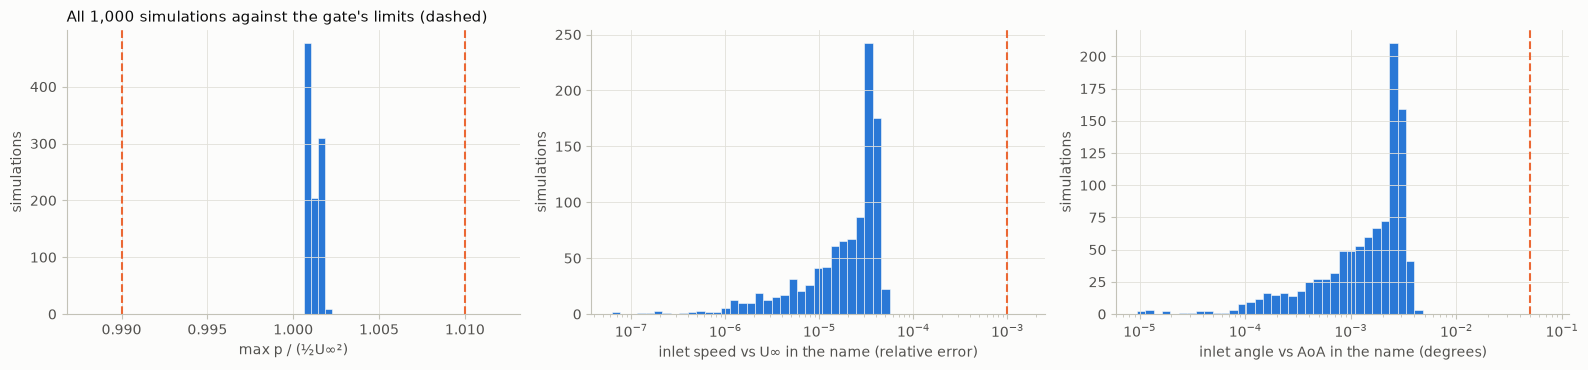

In [17]:
table = pq.read_table(INTERIM / "simulations.parquet").to_pandas()
etl = json.loads((INTERIM / "etl.json").read_text())
print(f"ETL: {etl['simulations']}, status {etl['status']!r}")
specs = [
    ("stagnation_ratio", "max p / (½U∞²)", quality.STAGNATION_RANGE, False),
    ("inlet_speed_rel_err", "inlet speed vs U∞ in the name (relative error)", (None, quality.INLET_SPEED_REL_TOL), True),
    ("inlet_angle_err_deg", "inlet angle vs AoA in the name (degrees)", (None, quality.INLET_ANGLE_TOL_DEG), True),
]
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, (column, label, limits, log) in zip(axes, specs):
    values = table[column].clip(lower=1e-12)
    high = limits[1]
    bins = np.logspace(np.log10(values.min()), np.log10(high * 1.5), 50) if log else np.linspace(limits[0] - 0.002, high + 0.002, 60)
    ax.hist(values, bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
    for limit in limits:
        if limit is not None:
            ax.axvline(limit, color=ORANGE, lw=1.5, ls="--")
    ax.set_xscale("log" if log else "linear")
    ax.set(xlabel=label, ylabel="simulations")
axes[0].set_title("All 1,000 simulations against the gate's limits (dashed)")
fig.tight_layout()
table[[c for c, *_ in specs]].describe().loc[["min", "50%", "max"]]

Every simulation agrees with its name by a wide margin: stagnation within 0.2 % where the gate allows 1 %, and inflow speed and angle within the solver's own precision. A mislabelled or swapped simulation would stand out by orders of magnitude. Without this check, a wrong folder name would silently pair one flow with another's inflow parameters, and the model would learn from it.

## 8. Target distributions and normalisation

Neural networks train best on inputs and targets of similar scale, so the ETL fits mean and standard deviation per channel. Two questions: fitted on which simulations, and is plain standardisation enough?

{'train': 720, 'val': 80, 'test': 200} (seed 0)


720 training simulations, three columns each, in 30 s
Spearman: lowest p vs ½U∞²: -0.53; lowest Cp vs U∞: +0.02; lowest Cp vs AoA: -0.75
thickness over the training set: 5.0 … 20.0 % of chord


,name,aoa_deg,thickness_pct,cp_min,speed_ratio
535,airFoil2D_SST_77.296_14.133_2.822_1.625_5.329,14.133,5.329,-27.1547,5.2276
659,airFoil2D_SST_87.75_14.191_0.722_3.837_1.0_6.198,14.191,6.198,-25.3219,5.0641
267,airFoil2D_SST_54.441_12.197_1.197_3.039_0.0_5.321,12.197,5.321,-23.6556,4.8826
272,airFoil2D_SST_54.627_14.036_4.031_1.872_5.46,14.036,5.460,-23.2895,4.8460


νₜ quantiles over training nodes: 1 % 2.3e-14, median 3.1e-09, 99 % 1.4e-02 m²/s → 12 orders of magnitude between the 1 % and 99 % quantiles


,mean,std,min,max,count
x,0.5007,0.7040,-2.1648,4.2321,1.2957e+08
y,0.0112,0.3364,-1.6456,1.6213,1.2957e+08
sdf,0.2317,0.4752,0.0000,3.6075,1.2957e+08
u_x,42.5208,29.7215,-224.4545,253.4238,1.2957e+08
u_y,9.8219,30.8552,-212.5035,442.1800,1.2957e+08
p,-450.3362,2985.0570,-97490.1484,4385.9351,1.2957e+08
nut,0.0008,0.0030,0.0000,0.0926,1.2957e+08
inlet_u_x,61.6692,17.8544,30.5710,93.3776,1.2957e+08
inlet_u_y,4.9165,6.2582,-7.1886,22.2922,1.2957e+08


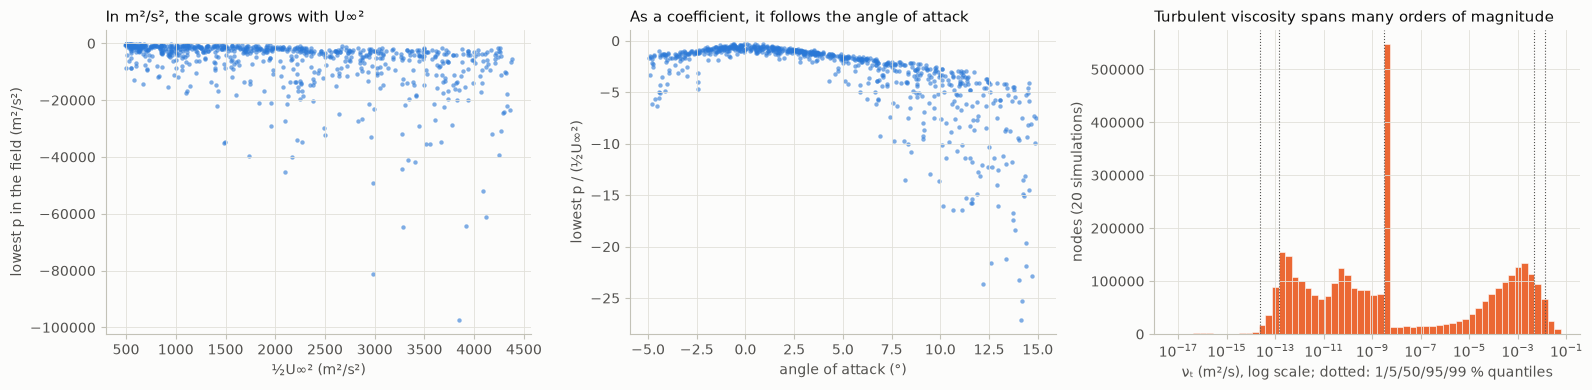

In [18]:
splits = json.loads((PROCESSED / "splits.json").read_text())
norm = json.loads((PROCESSED / "normalisation.json").read_text())
print({k: len(splits[k]) for k in ("train", "val", "test")}, f"(seed {splits['seed']})")

from scipy.stats import spearmanr

train = table[table.name.isin(splits["train"])].reset_index(drop=True)


def extremes(name: str) -> tuple[float, float]:
    nodes = pq.read_table(INTERIM / "simulations" / name / "nodes.parquet", columns=["u_x", "u_y", "p"]).to_pandas()
    return float(nodes.p.min()), float(np.hypot(nodes.u_x, nodes.u_y).max())


(train["p_min"], train["speed_max"]), seconds = timed(lambda: zip(*[extremes(n) for n in train.name]))
train["cp_min"] = train.p_min / (0.5 * train.u_inf**2)
train["speed_ratio"] = train.speed_max / train.u_inf
train["thickness_pct"] = train.naca_params.map(lambda params: params[-1])
print(f"{len(train)} training simulations, three columns each, in {seconds:.0f} s")
print(f"Spearman: lowest p vs ½U∞²: {spearmanr(train.p_min, train.u_inf**2)[0]:+.2f}; "
      f"lowest Cp vs U∞: {spearmanr(train.cp_min, train.u_inf)[0]:+.2f}; lowest Cp vs AoA: {spearmanr(train.cp_min, train.aoa_deg)[0]:+.2f}")
print(f"thickness over the training set: {train.thickness_pct.min():.1f} … {train.thickness_pct.max():.1f} % of chord")
display(train.nsmallest(4, "cp_min")[["name", "aoa_deg", "thickness_pct", "cp_min", "speed_ratio"]])

nut_sample = np.concatenate([
    pq.read_table(INTERIM / "simulations" / n / "nodes.parquet", columns=["nut"]).column("nut").to_numpy()
    for n in train.name.sample(20, random_state=0)
])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(0.5 * train.u_inf**2, train.p_min, s=10, color=BLUE, alpha=0.6, linewidths=0)
axes[0].set(xlabel="½U∞² (m²/s²)", ylabel="lowest p in the field (m²/s²)", title="In m²/s², the scale grows with U∞²")
axes[1].scatter(train.aoa_deg, train.cp_min, s=10, color=BLUE, alpha=0.6, linewidths=0)
axes[1].set(xlabel="angle of attack (°)", ylabel="lowest p / (½U∞²)", title="As a coefficient, it follows the angle of attack")
positive = nut_sample[nut_sample > 0]
axes[2].hist(positive, bins=np.logspace(np.log10(positive.min()), np.log10(positive.max()), 60), color=ORANGE,
             edgecolor=SURFACE, linewidth=0.4)
for q, value in norm["nut_quantiles"].items():
    axes[2].axvline(value, color=INK_2, lw=0.8, ls=":")
axes[2].set_xscale("log")
axes[2].set(xlabel="νₜ (m²/s), log scale; dotted: 1/5/50/95/99 % quantiles", ylabel="nodes (20 simulations)",
            title="Turbulent viscosity spans many orders of magnitude")
fig.tight_layout()
q = norm["nut_quantiles"]
print(f"νₜ quantiles over training nodes: 1 % {q['q01']:.1e}, median {q['q50']:.1e}, 99 % {q['q99']:.1e} m²/s "
      f"→ {np.log10(q['q99'] / q['q01']):.0f} orders of magnitude between the 1 % and 99 % quantiles")
pd.DataFrame(norm["channels"]).T[["mean", "std", "min", "max", "count"]]

**Decision: per-channel mean and standard deviation, fitted on the 720 training simulations only**, streamed one simulation at a time (130 million nodes don't fit in memory at once).

| Option | Verdict |
|---|---|
| Fit on all 1,000 simulations | Rejected. Test data would shape the preprocessing, so the test set would no longer be fully unseen. The effect is small, but it's the kind of leak that is easy to prevent and impossible to quantify afterwards. |
| Fit on all of `full_train`, validation included | Rejected. Validation chooses between models; it shouldn't shape their inputs either. |
| **Training simulations only** | **Chosen.** A unit test proves it: changing every validation and test simulation leaves `normalisation.json` byte-for-byte identical, while changing one training simulation moves it. |

**The extremes are real.** The lowest pressure coefficients, down to about −27, and local speeds over five times U∞ all belong to thin sections (5–6 % of chord) at 12–14°, the sharpest suction peaks in the dataset (table above). They pass every quality check and follow the physics, so they stay. But they stretch the standard deviations (`p` ranges to about −97,000 m²/s² against a standard deviation near 3,000), which a model trained on standardised values will feel.

**Left for the modelling stage, on purpose:**
- In m²/s² the pressure range grows with U∞². As a coefficient, `p / (½U∞²)`, it no longer depends on U∞ at all but on the angle of attack (middle plot). So predicting Cp rather than p may be easier to learn.
- νₜ spans about a dozen orders of magnitude between its 1 % and 99 % quantiles. Standardised raw, almost every node would be squeezed into a sliver near zero, so a log transform is the obvious candidate.

Both change what the model predicts, so they are modelling decisions to be made against a baseline, not data cleaning. The ETL supplies the statistics and quantiles to decide them.

## 9. What reading costs

Reading one `.vtu` with VTK takes over a second. A model trained on 720 meshes for hundreds of epochs can't pay that on every pass. But *why* is it slow?

**A second wrong first reading.** My first probe found Python reading a file's bytes at 69 MB/s, then VTK taking about 1 s to read the same, already-cached file. I concluded that decoding (base64 and zlib) was CPU-bound, and that moving the data off the Windows bind mount into the WSL2 filesystem wouldn't help. The measurement below separates the steps properly: it hands VTK the bytes from memory, so the decoding is timed on its own.

,seconds per mesh,minutes for 720 training meshes
Python reads the bytes,0.0800,0.9604
VTK decodes them from memory,0.1848,2.2179
VTK reads the file itself,1.0870,13.0437
pyarrow reads nodes + edges,0.0828,0.9939


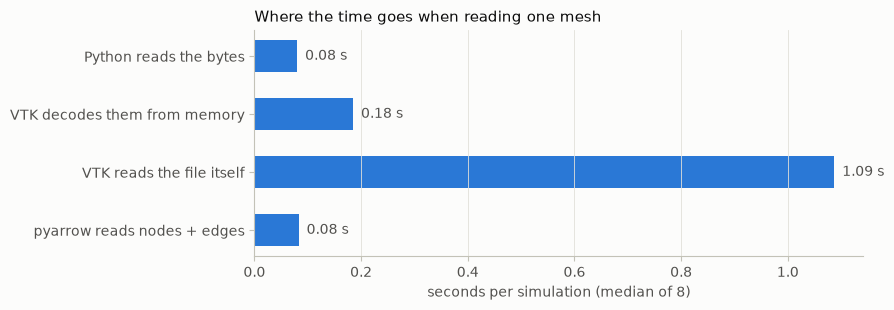

In [19]:
def vtk_reads_the_file(path: Path) -> int:
    reader = vtkXMLUnstructuredGridReader()
    reader.SetFileName(str(path))
    reader.Update()
    return reader.GetOutput().GetNumberOfPoints()


def vtk_decodes_from_memory(text: str) -> int:
    reader = vtkXMLUnstructuredGridReader()
    reader.ReadFromInputStringOn()
    reader.SetInputString(text)
    reader.Update()
    return reader.GetOutput().GetNumberOfPoints()


rows = []
for name in sims.name.sample(8, random_state=1):
    path = simulation_files(DATASET / name)[0]
    data, t_bytes = timed(path.read_bytes)
    n_from_memory, t_decode = timed(vtk_decodes_from_memory, data.decode("ascii"))
    n_from_file, t_file = timed(vtk_reads_the_file, path)
    assert n_from_memory == n_from_file
    sim_dir = INTERIM / "simulations" / name
    _, t_parquet = timed(lambda: (pq.read_table(sim_dir / "nodes.parquet"), pq.read_table(sim_dir / "edges.parquet")))
    rows.append({"MB": len(data) / 1e6, "Python reads the bytes": t_bytes, "VTK decodes them from memory": t_decode,
                 "VTK reads the file itself": t_file, "pyarrow reads nodes + edges": t_parquet})
bench = pd.DataFrame(rows)
medians = bench.drop(columns="MB").median()

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(medians.index[::-1], medians.values[::-1], color=BLUE, height=0.55)
for y, value in enumerate(medians.values[::-1]):
    ax.text(value, y, f"  {value:.2f} s", va="center", color=INK_2)
ax.set(xlabel="seconds per simulation (median of 8)", title="Where the time goes when reading one mesh")
ax.grid(axis="y", visible=False)
fig.tight_layout()
epoch = (medians * 720 / 60).rename("minutes for 720 training meshes")
pd.concat([medians.rename("seconds per mesh"), epoch], axis=1)

Decoding from memory is fast. Most of VTK's time goes to **reading the file through its own I/O path**, which makes many small reads, each crossing the Windows-to-Linux bind mount. Python's single bulk read of the same bytes is quick. So the first conclusion was wrong twice over: the work is I/O-bound, and the fix isn't moving the data but **reading each file in one go and handing VTK the bytes**. The ETL's reader (`src/etl/vtk_io.py`) does exactly that.

**Decision: decode each simulation once, into parquet, and never read VTK during training.** Even with the fast path, converting costs more per mesh than reading parquet, and that saving is paid on every epoch.

| Option | Verdict |
|---|---|
| Keep the VTK files and decode on every load | Rejected: the table above, multiplied by every epoch. |
| Move the data into the WSL2 filesystem | Not needed once each file is read in one go. It would also break the project's rule that copying the folder copies the data. |
| **Decode once, store as parquet** | **Chosen.** Two worker processes (the container's CPU limit) convert the whole dataset in one run, logged in `etl.json`. |

In [20]:
pd.Series(etl["timing"], name="etl.json timing").to_frame()

,etl.json timing
wall_s,601.900
workers,2.000
s_per_sim_median,1.187
s_per_sim_p95,1.293
sims_per_min,99.700


## 10. How it is stored

In [21]:
sizes = {"nodes.parquet": 0, "edges.parquet": 0, "surface.parquet": 0, "meta.json": 0}
for sim_dir in (INTERIM / "simulations").iterdir():
    for file in sim_dir.iterdir():
        sizes[file.name] += file.stat().st_size
raw_vtk = sum(f.stat().st_size for n in NAMES for f in simulation_files(DATASET / n))
display(pd.Series({**{k: v / 1e9 for k, v in sizes.items()}, "total interim": sum(sizes.values()) / 1e9,
                   "raw VTK, for comparison": raw_vtk / 1e9}, name="GB").to_frame())

import tempfile
edge_table = pq.read_table(INTERIM / "simulations" / example / "edges.parquet")
with tempfile.TemporaryDirectory() as tmp:
    pq.write_table(edge_table, f"{tmp}/plain.parquet", compression="zstd")
    plain = Path(f"{tmp}/plain.parquet").stat().st_size
delta = (INTERIM / "simulations" / example / "edges.parquet").stat().st_size
print(f"edges of one mesh ({edge_table.num_rows:,} rows): {plain / 1e6:.2f} MB with plain zstd, {delta / 1e6:.3f} MB delta-encoded ({plain / delta:.0f}× smaller)")

,GB
nodes.parquet,7.4701
edges.parquet,0.0478
surface.parquet,0.0009
meta.json,0.0006
total interim,7.5194
"raw VTK, for comparison",15.0333


edges of one mesh (363,588 rows): 2.39 MB with plain zstd, 0.050 MB delta-encoded (48× smaller)


**Decision: one directory per simulation holding three typed parquet tables** (`nodes`, `edges`, `surface`) and a `meta.json`. Every column keeps its source dtype, so the conversion is lossless, and a round-trip test proves it on real data.

| Option | Verdict |
|---|---|
| One big table for all simulations | Rejected. No per-simulation checkpoint or fault isolation: one bad mesh would block the batch, and an interrupted run would start over. Models load one simulation at a time anyway. |
| NumPy `.npz` or HDF5 | Rejected. No declared, enforced schema (`.npz`), or another dependency for less tooling (HDF5). Parquet is typed, columnar (a loader reads only the columns it needs, as section 8 did), and compressed. |
| **Parquet per simulation, written atomically** | **Chosen.** Each simulation is written to `<name>.partial/` and renamed when whole, so a re-run knows exactly what is finished. |

The edge table lists node pairs sorted by `src`, so consecutive values differ by small amounts. Delta encoding stores those differences instead of the values, which is why the graph of a 180,000-node mesh fits in about 50 KB.

## 11. Summary of decisions

| Topic | Decision | Rejected | Evidence |
|---|---|---|---|
| Source | Authors' raw `Dataset.zip`, pinned by size, ETag and SHA-256 | PyG dataset (no mesh cells), `airfrans` package (extra dependency, unmaintained) | §1 |
| Split | Manifest `full_train` / `full_test`, by simulation; validation = 80 of `full_train`, seed 0 | Point-level split (leaks geometry); home-made split (not comparable) | §2 |
| Values | Point data, z and U_z dropped (U_z is round-off) | Cell-centred data (needs a second graph) | §3 |
| Graph | Sides of the mesh's quads, about 4 neighbours per node | k-NN (no neighbours along the wall in the boundary layer; a larger k cuts through the airfoil), radius graph (degree from 0 to thousands) | §4 |
| Surface | Exact coordinate match, cross-checked against U = 0 and distance = 0 | Distance tolerance (works here, but a mesh-specific parameter that fails silently) | §5 |
| Normals | Flipped to point into the fluid | Keeping the inward vectors (a sign to remember forever) | §6 |
| Pressure | Kinematic gauge pressure as stored; Cp = p / (½U∞²) | Converting with an assumed density | §7 |
| Labels | Every folder name checked against stagnation pressure and inflow | Trusting folder names | §7 |
| Normalisation | Mean and std per channel, training simulations only, streamed | Fitting on all or on train + validation (leakage) | §8 |
| Reading | Read each file in one go, decode in memory, once, into parquet | Decoding VTK every epoch; moving data to WSL2 | §9 |
| Storage | Typed parquet per simulation, atomic, delta-encoded edges | One big table, `.npz`, HDF5 | §10 |